Test Accuracy: 100.0%
Precision:     nan%
Recall:        nan%
Confusion:     TP=0 TN=100 FP=0 FN=0


C:\Users\HP\AppData\Local\Temp\ipykernel_9228\3827625586.py:46: RuntimeWarning: invalid value encountered in scalar divide
  print(f"Precision:     {tp/(tp+fp):.1%}")
C:\Users\HP\AppData\Local\Temp\ipykernel_9228\3827625586.py:47: RuntimeWarning: invalid value encountered in scalar divide
  print(f"Recall:        {tp/(tp+fn):.1%}")



    Income   Credit   Debt  Years   Score   Decision
  ──────── ──────── ────── ────── ─────── ──────────
      7000      740   0.20   8.0   0.999   Approved
      2000      550   0.70   1.0   0.002     Denied
      4500      650   0.35   4.0   0.863   Approved
      1800      500   0.80   0.5   0.002     Denied


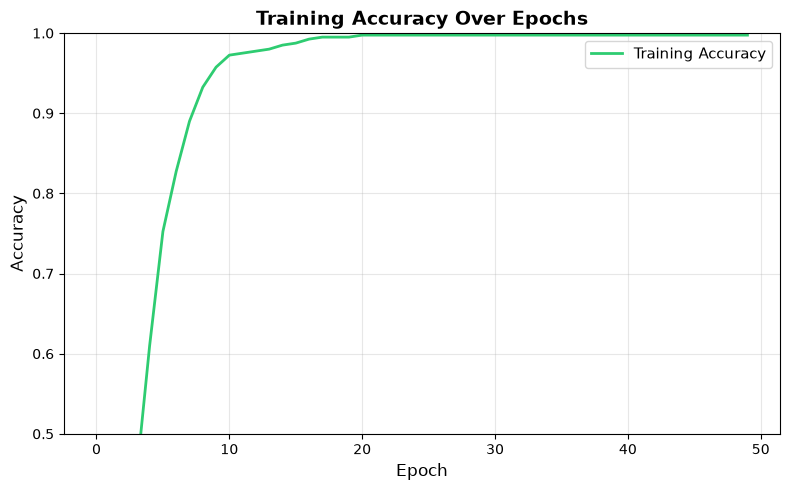

In [1]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

# --- Generate Synthetic Loan Data ---
np.random.seed(42)
n = 500

X = np.column_stack([
    np.concatenate([np.random.normal(6000, 1500, 250), np.random.normal(2500, 1000, 250)]),
    np.concatenate([np.random.normal(720, 40, 250),   np.random.normal(580, 50, 250)]),
    np.concatenate([np.random.normal(0.25, 0.08, 250), np.random.normal(0.55, 0.1, 250)]),
    np.concatenate([np.random.normal(6, 2, 250),       np.random.normal(2, 1.5, 250)])
]).astype(np.float32)

y = np.concatenate([np.ones(250), np.zeros(250)]).reshape(-1, 1)

# --- Normalize & Split ---
mean, std = X.mean(0), X.std(0)
X = (X - mean) / std

split = 400
X_train, X_test = X[:split], X[split:]
y_train, y_test = y[:split], y[split:]

# --- Build & Train Model ---
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(4,)),
    tf.keras.layers.Dense(8, activation='tanh'),
    tf.keras.layers.Dense(1, activation='sigmoid')
])
model.compile(optimizer='rmsprop', loss='binary_crossentropy', metrics=['accuracy'])

history = model.fit(X_train, y_train, epochs=50, verbose=0)

# --- Evaluate ---
y_pred = (model.predict(X_test, verbose=0).flatten() >= 0.5).astype(int)
y_true = y_test.flatten().astype(int)
acc = np.mean(y_pred == y_true)
tp = np.sum((y_pred==1)&(y_true==1))
tn = np.sum((y_pred==0)&(y_true==0))
fp = np.sum((y_pred==1)&(y_true==0))
fn = np.sum((y_pred==0)&(y_true==1))

print(f"Test Accuracy: {acc:.1%}")
print(f"Precision:     {tp/(tp+fp):.1%}")
print(f"Recall:        {tp/(tp+fn):.1%}")
print(f"Confusion:     TP={tp} TN={tn} FP={fp} FN={fn}")

# --- Predict New Applicants ---
new = np.array([[7000,740,0.20,8],[2000,550,0.70,1],[4500,650,0.35,4],[1800,500,0.80,0.5]])
new_norm = (new - mean) / std
preds = model.predict(new_norm, verbose=0).flatten()

print(f"\n  {'Income':>8} {'Credit':>8} {'Debt':>6} {'Years':>6} {'Score':>7} {'Decision':>10}")
print(f"  {'─'*8} {'─'*8} {'─'*6} {'─'*6} {'─'*7} {'─'*10}")
for row, p in zip(new, preds):
    print(f"  {row[0]:>8.0f} {row[1]:>8.0f} {row[2]:>6.2f} {row[3]:>5.1f} {p:>7.3f} {'Approved' if p>=0.5 else 'Denied':>10}")

# --- Training Curve Plot ---
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(history.history['accuracy'], color='#2ecc71', linewidth=2, label='Training Accuracy')
ax.set_xlabel('Epoch', fontsize=12)
ax.set_ylabel('Accuracy', fontsize=12)
ax.set_title('Training Accuracy Over Epochs', fontsize=14, fontweight='bold')
ax.set_ylim(0.5, 1.0)
ax.legend(fontsize=11)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()